In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Simple Derivative

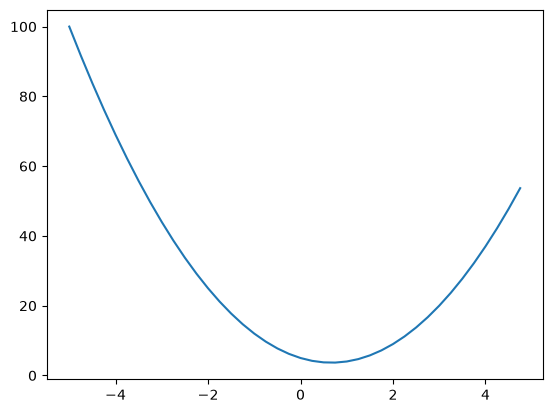

In [2]:
def f(x):
    return 3*x**2 - 4*x +5
f(3.0)
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs, ys)


In [3]:
h = 0.0000001
x = -3
(f(x+h)-f(x))/h

-21.999999688659955

# Partial Derivative

In [4]:
a = 2
b = -3
c = 10.0
d = a*b +c
print(d)

4.0


In [5]:
a = 2
b = -3
c = 10.0
d = a*b +c
print(d)

h = 0.0000001
d1 = a*b + c
a += h
d2 = a*b + c

print("d1", d1)
print("d2", d2)
print((d2-d1)/h)


4.0
d1 4.0
d2 3.9999997
-2.9999999995311555


In [6]:
def g(a,b,c):
    return a*b+c
def partial_derivative(n, h):
    if n==1:
        return (g(a+h,b,c)-g(a,b,c))/h
    if n==2:
        return (g(a,b+h,c)-g(a,b,c))/h
    if n==3:
            return (g(a,b,c+h)-g(a,b,c))/h
print(partial_derivative(1,h))
print(partial_derivative(2,h))
print(partial_derivative(3,h))

-2.9999999906493713
2.0000001033082526
0.999999993922529


# Data Structure

In [7]:
class Value: 

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data+other.data, (self, other), _op='+') 

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward

        return out
    def __radd__(self, other):
        return self + other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data*other.data, (self, other), _op='*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward

        return out
    def __rmul__(self, other):
        return self * other

    def __truediv__(self, other):
        return self * other ** -1

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self, ), f"**{other}")

        def _backward():
            self.grad += other * (self.data**(other - 1)) * out.grad
        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), "exp")

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out

    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [8]:
a = Value(2.0)
b = Value(4.0)
a-b

Value(data=-2.0)

In [9]:
# example of using the data structure
a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10.0, label = 'c')
e = a*b; e.label = 'e'
d = e+c; d.label = 'd'
f = Value(-2.0, label = 'f')
L = d * f; L.label = "L"
print(L)
print(L._prev)

Value(data=-8.0)
{Value(data=-2.0), Value(data=4.0)}


# Operation Visualization


In [10]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    # create a digraph object
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})

    nodes, edges = trace(root)
    for n in nodes:
        # for every value in the graph, create a rectangular node for it
        node_id = str(id(n))
        dot.node(name=node_id, label="{%s | data %.4f | %.4f}"%(n.label, n.data, n.grad), shape = "record")
        if n._op:
            # if this value is a result of an operation, create an operation node for it
            dot.node(name=node_id + n._op, label = n._op)
            # connect operation node to the value
            dot.edge(node_id + n._op, node_id)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


In [11]:
L.grad = 1 # dL/dL
f.grad = d.data # dL/df
d.grad = f.data # dL/dd
e.grad = 1 * d.grad # dL/de
c.grad = 1 * d.grad # dL/dc
a.grad = b.data * e.grad # dL/da
b.grad = a.data * e.grad # dL/db

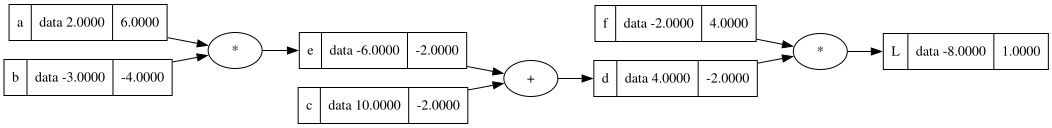

In [12]:
draw_dot(L)

# Simple Model of a neural network

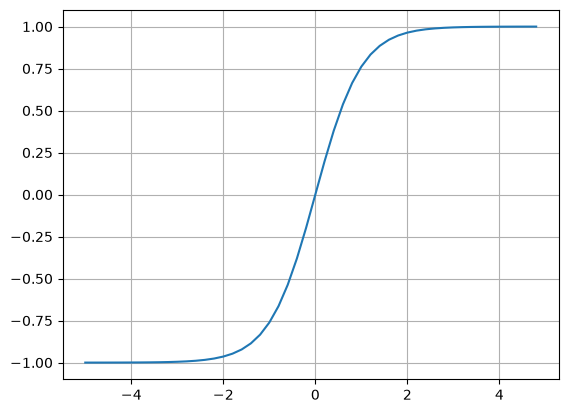

In [13]:
# plot of tanh
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid()

In [14]:
# inputs x1, x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label = "x2")
# weights w1, w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron
b = Value(6.88137, label="b")
# x1w1 + x2w2 +b
x1w1 = x1*w1; x1w1.label="x1*w1"
x2w2 = x2*w2; x2w2.label="x2*w2"
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label="x1w1 + x2w2"
n = x1w1x2w2 + b; n.label="n"
o = n.tanh(); o.label="o"
o.backward()


In [15]:
# manual back propogation
o.grad = 0 # do/do
n.grad = 1 - o.data ** 2  # do/dn
b.grad = 1  # do/db
x1w1x2w2.grad = 1 * n.grad  # do/dx1w1x2w2
x1w1.grad = 1 * x1w1x2w2.grad  # do/dx1w1
x2w2.grad = 1 * x1w1x2w2.grad  # do/dx2w2
w1.grad = x1.data * x1w1.grad  # do/dw1
x1.grad = w1.data * x1w1.grad  # do/dx1
w2.grad = x2.data * x2w2.grad  # do/dw2
x2.grad = w2.data * x2w2.grad  # do/dx2

In [16]:
# automated back propagation
o.grad = 1.0
o._backward()
n._backward()
b._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()


In [17]:
# topological sort, ensuring everything related to the final node is included 
# in a list topo in a topological order (earlier values are put first in the 
# list)
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)

o.grad = 1.0
for node in reversed(topo):
    node._backward()

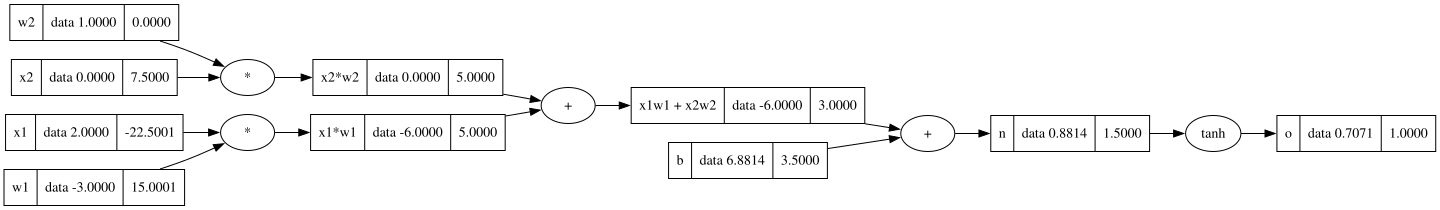

In [18]:
draw_dot(o)

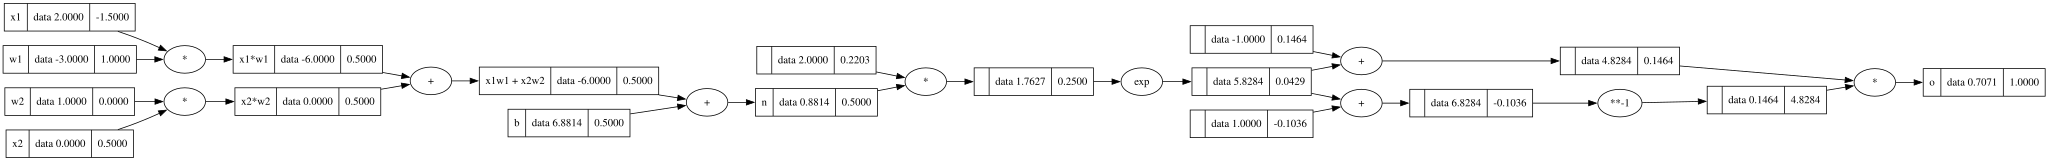

In [19]:
# inputs x1, x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label = "x2")
# weights w1, w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron
b = Value(6.88137, label="b")
# x1w1 + x2w2 +b
x1w1 = x1*w1; x1w1.label="x1*w1"
x2w2 = x2*w2; x2w2.label="x2*w2"
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label="x1w1 + x2w2"
n = x1w1x2w2 + b; n.label="n"
# --------
e = (2*n).exp()
o = (e-1)/(e+1)
# --------
o.label="o"
o.backward()

draw_dot(o)


### More Examples with back propogation with one variable used multiple times

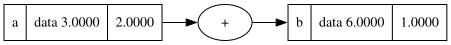

In [20]:
a = Value(3.0, label="a")
b = a + a; b.label="b"
b.backward()
draw_dot(b)

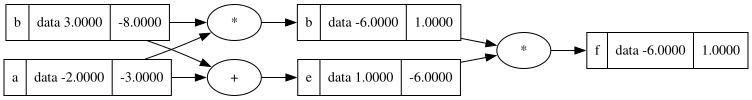

In [21]:
a = Value(-2.0, label="a")
b = Value(3.0, label="b")
d = a * b; d.label="b"
e = a + b; e.label="e"
f = d * e; f.label="f"
f.backward()

draw_dot(f)

# Implementation for Pytorch

In [22]:
import torch

In [ ]:
x1 = torch.tensor(2.0, requires_grad=True).double()
x2 = torch.tensor(0.0, requires_grad=True).double()
w1 = torch.tensor(-3.0, requires_grad=True).double()
w2 = torch.tensor(1.0, requires_grad=True).double()
b = torch.tensor(6.88137, requires_grad=True).double()
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

